### Importing Libraries

In [1]:
#import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,accuracy_score,recall_score
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('/kaggle/input/datasets/dileep070/heart-disease-prediction-using-logistic-regression/framingham.csv')

In [3]:
df.head(5)

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [4]:
df.shape

(4238, 16)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


In [6]:
df.isnull().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

In [7]:
#handling missing values
df['education'].fillna(df['education'].mode()[0],inplace=True)

<Axes: xlabel='cigsPerDay', ylabel='Count'>

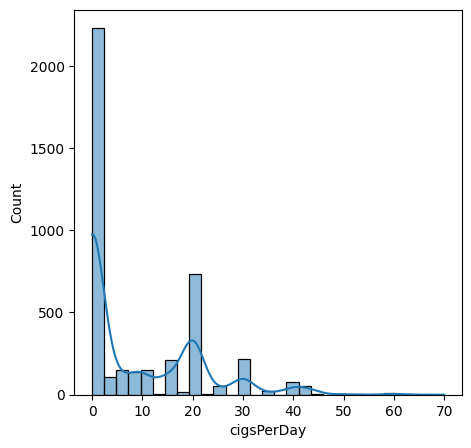

In [8]:
plt.figure(figsize=(5,5))
sns.histplot(df['cigsPerDay'],kde=True)

<Axes: xlabel='cigsPerDay'>

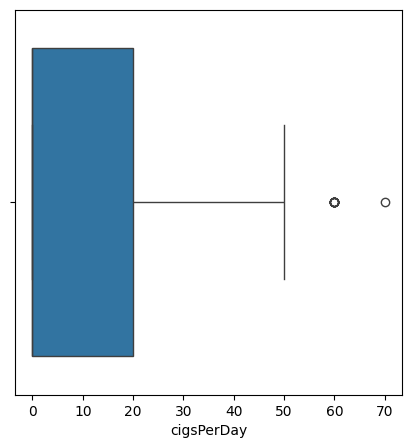

In [9]:
plt.figure(figsize=(5,5))
sns.boxplot(x=df['cigsPerDay'])

In [10]:
mediansmoker = df.loc[df['currentSmoker'] == 1, 'cigsPerDay'].median()

df.loc[(df['currentSmoker']==1) & (df['cigsPerDay'].isnull()),'cigsPerDay'] = mediansmoker

In [11]:
df['BPMeds'].value_counts()

BPMeds
0.0    4061
1.0     124
Name: count, dtype: int64

In [12]:
df['BPMeds'].fillna(0,inplace=True)

In [13]:
df['BPMeds'].value_counts()

BPMeds
0.0    4114
1.0     124
Name: count, dtype: int64

In [14]:
df['totChol'].value_counts()

totChol
240.0    85
220.0    70
260.0    62
210.0    61
232.0    59
         ..
453.0     1
347.0     1
373.0     1
385.0     1
119.0     1
Name: count, Length: 248, dtype: int64

<Axes: xlabel='totChol', ylabel='Count'>

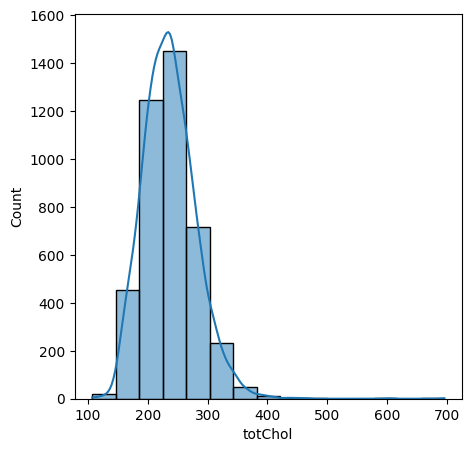

In [15]:
plt.figure(figsize=(5,5))
sns.histplot(df['totChol'],bins=15,kde=True)

In [16]:
df.fillna(df['totChol'].median(),inplace=True)

In [17]:
df['BMI'].value_counts()

BMI
234.00    19
22.54     18
23.48     18
22.19     18
22.91     18
          ..
33.37      1
33.02      1
20.45      1
20.96      1
18.63      1
Name: count, Length: 1364, dtype: int64

In [18]:
df.fillna(df['BMI'].median(),inplace=True)

In [19]:
df['heartRate'].value_counts()

heartRate
75.0     563
80.0     385
70.0     305
60.0     231
85.0     227
        ... 
97.0       1
99.0       1
143.0      1
101.0      1
46.0       1
Name: count, Length: 74, dtype: int64

In [20]:
df = df.dropna(subset=['heartRate'])

<Axes: xlabel='glucose', ylabel='Count'>

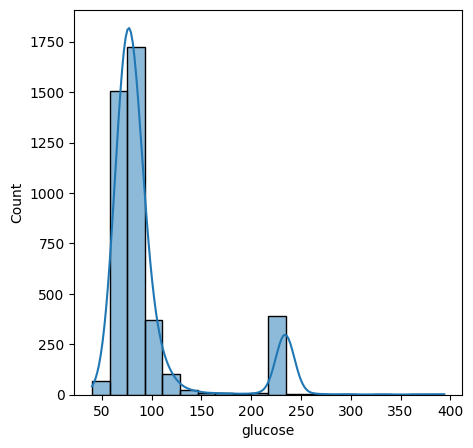

In [21]:
plt.figure(figsize=(5,5))
sns.histplot(df['glucose'],bins=20,kde=True)

In [22]:
df.fillna(df['glucose'].median(),inplace=True)

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4238 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4238 non-null   float64
 5   BPMeds           4238 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4238 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4238 non-null   float64
 13  heartRate        4238 non-null   float64
 14  glucose          4238 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


<Axes: >

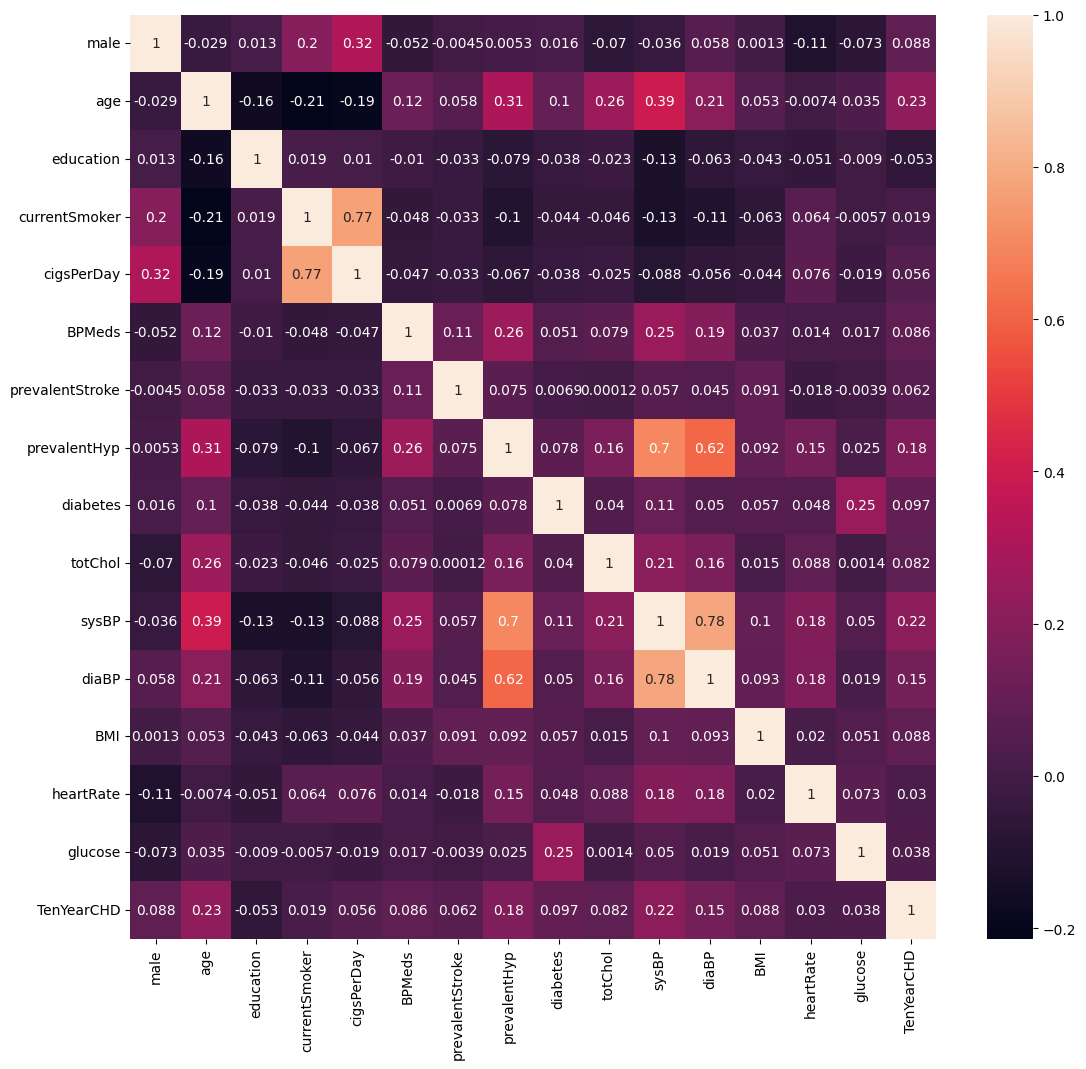

In [24]:
#checking corr
plt.figure(figsize=(13,12))
sns.heatmap(df.corr(),annot=True)

In [25]:
X = df.drop('TenYearCHD',axis=1) # independant feature
y = df['TenYearCHD'] # dependant feature

### Splitting data into train and validation

In [26]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)


### Performig scaling

In [27]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [28]:
smote = SMOTE(random_state=42)
X_train,y_train = smote.fit_resample(X_train,y_train)

### Model training

In [29]:
logistic = LogisticRegression(random_state=42)
logistic.fit(X_train,y_train)

LogisticRegression(random_state=42)

In [30]:
y_pred = logistic.predict(X_test)

### Evaluation

In [31]:
matrix = confusion_matrix(y_test,y_pred)
accuracy = accuracy_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
#printting
print(f'Confusion matrix score: {matrix}')
print(f'Accuracy score: {accuracy}')
print(f'Recall score: {recall}')

Confusion matrix score: [[464 260]
 [ 41  83]]
Accuracy score: 0.6450471698113207
Recall score: 0.6693548387096774
